<a href="https://colab.research.google.com/github/DanielV-13/ADFM---PA_03_neural_network_torch.ipynb/blob/main/ADFM_PA_03_neural_network_torch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/vischia/adfm/blob/master/PA_03_neural_network_torch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis de Datos en Física Moderna
@Pietro Vischia (pietro.vischia@cern.ch)


## Pietro Vischia (Universidad de Oviedo and ICTEA), pietro.vischia@cern.ch, vischia@uniovi.es

### A few global settings

- If you run on colab, set to `True` the relevant environmental variable.

This tutorial will assume you have a few GB free wherever you are running (locally on your machine, or in your google drive account)


In [1]:
runOnColab = False

In [2]:
if runOnColab:
    from google.colab import drive
    drive.mount('/content/drive')

    # Crear la carpeta adfm en Google Drive si no existe
    import os
    os.makedirs("/content/drive/MyDrive/adfm", exist_ok=True)

    %cd "/content/drive/MyDrive/adfm/"

    # Comentamos esta línea para que no vuelva a saltar el aviso de reinicio:
    !pip install livelossplot shap uproot

In [5]:
# Instalamos la dependencia necesaria si no está presente
!pip install -q uproot

# =====================================================================
# CÉLULA DE IMPORTACIÓN: ENTORNO DE LIBRERÍAS CIENTÍFICAS Y DE MACHINE LEARNING
# =====================================================================

# 1. Configuración de visualización gráfica
import matplotlib
%matplotlib inline
# Renderiza gráficos directamente en el cuaderno de Colab
import matplotlib.pyplot as plt  # Interfaz principal para trazar curvas y histogramas


# 2. Utilidades del sistema, archivos y serialización
import glob     # Búsqueda de rutas de archivos mediante patrones comodín
import os       # Interacción con el sistema operativo y directorios
import re      # Procesamiento de expresiones regulares para texto
import math    # Funciones matemáticas estándar de Python
import socket   # Gestión de conexiones y nombres de red
import json    # Lectura y escritura de archivos estructurados JSON
import pickle  # Serialización y guardado de objetos/modelos en binario
import gzip    # Manejo de compresión y descompresión de archivos .gz
import copy    # Copias superficiales y profundas de objetos
import array    # Manipulación eficiente de arreglos tipados básicos
import datetime   # Gestión de marcas de tiempo y fechas
from timeit import default_timer as timer   # Medición precisa de tiempos de ejecución de código


# 3. Computación numérica y soporte iterativo
import numpy as np            # Operaciones vectoriales y matriciales de alto rendimiento
import numpy.lib.recfunctions as recfunc # Herramientas para arreglos estructurados de NumPy
from tqdm import tqdm    # Barreras de progreso interactivas para bucles pesados


# 4. Computación científica y estadística avanzada (SciPy)
from scipy.optimize import newton     # Método de Newton-Raphson para búsqueda de raíces
from scipy.stats import norm      # Funciones de distribución de probabilidad normal/gaussiana


# 5. Entrada/Salida para física de altas energías
import uproot   # Lectura nativa de archivos .root del CERN en estructuras de Python



# 6. Aprendizaje automático y métricas de evaluación (Scikit-Learn)
import sklearn   # Biblioteca principal de Machine Learning
from sklearn.model_selection import train_test_split  # División estratificada de datos (train/test)
from sklearn.utils import shuffle   # Mezcla aleatoria de filas para evitar sesgos de orden
from sklearn.metrics import roc_curve, auc, accuracy_score  # Métricas: Curvas ROC, AUC y precisión
from sklearn.tree import export_graphviz    # Visualización estructural de árboles de decisión
from sklearn.inspection import permutation_importance   # Importancia de características en modelos


# Bloque de compatibilidad robusta para versiones de scikit-learn >= 0.24
try:
    # See #1137: this allows compatibility for scikit-learn >= 0.24
    from sklearn.utils import safe_indexing
except ImportError:
    from sklearn.utils import _safe_indexing

# 7. Manipulación de estructuras tabulares
import pandas as pd   # Creación y manipulación de DataFrames bidimensionales

You have programmed a neural network from scratch. Now you will use the library `torch`.

---
### 🔄 Transición: De la Red Neuronal "Desde Cero" (PA02) a PyTorch (PA03)

* **Lo que hicimos en el PA02 (Desde Cero):**
  * Construimos una red neuronal profunda completamente a mano utilizando únicamente `NumPy`.
  * Programamos explícitamente las funciones de activación, la propagación hacia adelante (*forward pass*), la retropropagación (*backpropagation*), las derivadas matriciales y la actualización de pesos.
  * Esto nos otorgó una comprensión matemática y rigurosa de cómo se propagan los gradientes en el modelo.

* **Lo que haremos ahora en el PA03 (Usando `torch`):**
  * Damos el salto al uso de **PyTorch (`torch`)**, un framework moderno diseñado específicamente para operaciones con tensores y optimización en hardware acelerado.
  * Aprovecharemos la infraestructura nativa de diferenciación automática (*autograd*) para el seguimiento de parámetros.
  * Implementaremos la gestión de datos mediante `Dataset` y `DataLoader` para optimizar el entrenamiento por lotes (*minibatches*).
  * Definiremos modelos heredando de `nn.Module`, estructuraremos bucles manuales de entrenamiento y test, y abordaremos escenarios avanzados como:
    1. **Estandarización de características** con `StandardScaler`.
    2. **Clasificación Multiclase** mediante codificación *one-hot* y matrices de confusión.
    3. **Regresión** del momento transversal ($p_T$) del bosón de Higgs.
---

In [6]:
# =====================================================================
# INSTALACIÓN E IMPORTACIÓN DE MÓDULOS DE PYTORCH
# =====================================================================

# 1. Instalamos las librerías necesarias: 'torch' (motor principal de redes neuronales)
#    y 'torchinfo' (para inspeccionar la arquitectura y número de parámetros de la red).
!pip install torch torchinfo

# 2. Importamos 'torchinfo' para obtener resúmenes detallados de las capas del modelo.
import torchinfo

# 3. Importamos la librería principal de PyTorch para el manejo de tensores y operaciones automáticas.
import torch

# 4. Fijamos una semilla aleatoria (seed) en PyTorch para garantizar la reproducibilidad
#    de los pesos iniciales de la red en cada ejecución.
torch.manual_seed(0)

# 5. Importamos 'torch.nn', el módulo fundamental que contiene las capas base para redes neuronales (como capas lineales, funciones de pérdida, etc.).
import torch.nn as nn

# 6. Importamos la clase base 'Dataset' de PyTorch para estructurar y gestionar nuestros propios conjuntos de datos.
from torch.utils.data import Dataset

# 7. Importamos la clase 'DataLoader' para manejar la carga eficiente de datos en lotes (batches) y mezclar (shuffle) los eventos.
from torch.utils.data import DataLoader


# 8. Importamos 'torch.nn.functional' (comúnmente abreviado como F), que contiene funciones de activación
#    y operaciones matemáticas sin estado (como ReLU, Sigmoid, etc.) que se pueden usar directamente.
import torch.nn.functional as F

---
## 🧠 ¿Qué es PyTorch (`torch`) y cómo funciona por dentro?

**PyTorch** es uno de los frameworks más importantes y utilizados hoy en día en investigación científica (como en el CERN) e inteligencia artificial. Su éxito se debe a que combina la flexibilidad y sintaxis de **NumPy** con dos capacidades fundamentales:
1. **Aceleración por hardware (GPU):** Permite mover matrices enormes de la CPU a la tarjeta gráfica (`cuda`) con una sola instrucción para entrenar redes en segundos.
2. **Diferenciación Automática (`autograd`):** Construye un grafo computacional dinámico mientras ejecutas operaciones y calcula automáticamente todas las derivadas parciales por ti.

---

### 🧩 Los Módulos Principales de PyTorch (y su equivalente en lo que ya sabes)

En lugar de programar todo en un solo bloque monolítico, PyTorch divide el flujo de trabajo en módulos especializados. Así es como se relacionan con los conceptos que ya dominas:

| Módulo / Componente | ¿Para qué se usa? | Relación con lo que ya viste antes |
| :--- | :--- | :--- |
| **`torch.Tensor`** | Es la estructura de datos central (arreglos multidimensionales). Almacena los datos, los pesos y el historial de operaciones para calcular gradientes. | Es el equivalente directo a los **`np.ndarray` de NumPy**, pero con esteroides: soporta GPU y lleva registro de derivadas (como los **números duales** que implementaste para diferenciación automática). |
| **`torch.autograd`** | Motor invisible que rastrea cada operación matemática sobre un tensor y ejecuta la regla de la cadena hacia atrás cuando llamas a `.backward()`. | Reemplaza todo el cálculo manual de derivadas matriciales ($\frac{\partial L}{\partial W}$, $\frac{\partial L}{\partial b}$) que programaste a mano en el *backpropagation* del **PA02**. |
| **`torch.nn`** | Contiene los bloques de construcción de la red: capas lineales (`nn.Linear`), funciones de activación (`nn.ReLU`, `nn.Sigmoid`), *Dropout* y funciones de pérdida (`nn.MSELoss`, `nn.CrossEntropyLoss`). | Sustituye a las funciones matemáticas que escribiste desde cero en el **PA02** (como `z = W @ x + b` o la fórmula de ReLU y Sigmoide). Además, `nn.Module` agrupa y rastrea automáticamente todos los pesos entrenables. |
| **`torch.nn.functional` (`F`)** | Versión puramente funcional (sin estado ni pesos internos guardados) de activaciones, pérdidas y transformaciones (ej. `F.one_hot`, `F.relu`). | Es equivalente a llamar a funciones matemáticas sueltas de `numpy` o `scipy` sobre un arreglo sin crear un objeto o capa permanente. |
| **`torch.optim`** | Implementa los algoritmos de optimización que actualizan los pesos de la red usando los gradientes calculados (`SGD`, `Adam`, etc.) y planificadores (`lr_scheduler`). | Reemplaza el bucle manual de actualización de pesos (`W = W - lr * dW`) que hiciste en el **PA02**, añadiendo estrategias avanzadas como momento o ajuste dinámico del *learning rate*. |
| **`torch.utils.data`** | Proporciona `Dataset` (cómo acceder a cada evento/fila) y `DataLoader` (cómo agruparlos en lotes, mezclarlos y cargarlos en paralelo). | Automatiza por completo los iteradores, el *shuffling* y la división en *minibatches* que tuviste que programar manualmente en el ejercicio de esquemas de entrenamiento del **PA02**. |

---

### ⚙️ ¿Cómo se conectan estas piezas durante el entrenamiento?

El ciclo de vida de una iteración (un *batch*) en PyTorch sigue siempre estos 5 pasos explícitos:

1. **Entrega de datos (`DataLoader`):** Extrae un *minibatch* de tensores $(X, y)$ y los envía al dispositivo elegido (`CPU` o `GPU`).
2. **Propagación hacia adelante (`nn.Module`):** Pasas los datos por el modelo (`yhat = model(X)`). Mientras tanto, `autograd` va anotando en secreto cada suma y multiplicación en un grafo.
3. **Cálculo del error (`loss_fn`):** Comparas la predicción `yhat` con la etiqueta real `y` para obtener un único escalar de pérdida (`loss`).
4. **Retropropagación (`autograd`):**
   * Limpias los gradientes de la iteración anterior con `optimizer.zero_grad()` (para que no se sumen).
   * Llamas a `loss.backward()`, y PyTorch recorre el grafo hacia atrás calculando $\nabla_W L$ para cada parámetro.
5. **Actualización de parámetros (`torch.optim`):** Ejecutas `optimizer.step()`, aplicando la regla de descenso de gradiente para modificar los pesos y reducir el error en la siguiente vuelta.
---

In [ ]:
# This line ownloads the data only if you haven't done so yet

if not os.path.isfile("data/signal_blind20.root"):
    !mkdir data; cd data/; wget https://www.hep.uniovi.es/vischia/lisbon_ml_school/lisbon_ml_school_tth.tar.gz; tar xzvf lisbon_ml_school_tth.tar.gz; rm lisbon_ml_school_tth.tar.gz; cd -;
else:
    print("Data were already downloaded, I am not downloading them again.")

Data were already downloaded, I am not downloading them again.


The data set is made of three files, one per background (`background_1` is ttW, `background_2`is Drell-Yan.
The ttH signal events file corresponds to only a percentage of the full data set: the rest is used in the data challenge (for schools where I offer a data challenge).

In [ ]:
import uproot

sig = uproot.open('data/signal_blind20.root')['Friends'].arrays(library="pd")
bk1 = uproot.open('data/background_1.root')['Friends'].arrays(library="pd")
bk2 = uproot.open('data/background_2.root')['Friends'].arrays(library="pd")


## Data inspection

See the notebook `02_data_inspection.ipynb`

REVISAR EL CUADERNO ANTIGUO Y ENTENDER PORQUE SE HACEN ESOS FILTROS en los DATOS


In [ ]:
# Create a new column 'label' and set its value to 1 or 0 for all rows (=events)
sig['label'] = 1
bk1['label'] = 0
bk2['label'] = 0

# Merge the two backgrounds into one dataframe
bkg = pd.concat([bk1, bk2])

print(f"bkg1 shape {bk1.shape}")
print(f"bkg2 shape {bk2.shape}")
print(f"bkg1+bkg2 shape {bkg.shape}")

# Merge the signal and background into one dataframe
print(f" Signal shape {sig.shape}")
print(f" Bkg shape {bkg.shape}")

data = pd.concat([sig,bkg])

print(f" Data shape {data.shape}")
print(data.columns)

# Filter data
data=data[data['Hreco_Lep2_pt']==-99]
# Drop unneeded features
data = data.drop(["index","Hreco_Lep2_pt", "Hreco_Lep2_eta", "Hreco_Lep2_phi", "Hreco_Lep2_mass",
                  "Hreco_evt_tag","Hreco_HTXS_Higgs_pt", "Hreco_HTXS_Higgs_y", "Hreco_More5_Jets_pt", "Hreco_More5_Jets_eta", "Hreco_More5_Jets_phi", "Hreco_More5_Jets_mass",], axis=1 )


print(f" Data shape {data.shape}")
print(data.columns)
print(f"In this dataframe we finally have {data[data['label']==1].shape[0]} signal and {data[data['label']==0].shape[0]} background events")
print("Sanity check: look for NAN numbers in any of the rows or columns")
print(data.isna().any())


data = data.sample(frac=1).reset_index(drop=True)
data.head(10)


print("There are NaN-filled elements:", data.isna().any().any())

X = data.drop(["label"], axis=1)
y = data["label"]

print(f"data shape {data.shape}")
print(f"input feature shape {X.shape}")
print(f"label (=target) shape {y.shape}")


bkg1 shape (556648, 35)
bkg2 shape (1034904, 35)
bkg1+bkg2 shape (1591552, 35)
 Signal shape (299287, 36)
 Bkg shape (1591552, 35)
 Data shape (1890839, 36)
Index(['index', 'Hreco_Lep0_pt', 'Hreco_Lep1_pt', 'Hreco_Lep2_pt',
       'Hreco_HadTop_pt', 'Hreco_All5_Jets_pt', 'Hreco_More5_Jets_pt',
       'Hreco_Jets_plus_Lep_pt', 'Hreco_Lep0_eta', 'Hreco_Lep1_eta',
       'Hreco_Lep2_eta', 'Hreco_HadTop_eta', 'Hreco_All5_Jets_eta',
       'Hreco_More5_Jets_eta', 'Hreco_Jets_plus_Lep_eta', 'Hreco_Lep0_phi',
       'Hreco_Lep1_phi', 'Hreco_Lep2_phi', 'Hreco_HadTop_phi',
       'Hreco_All5_Jets_phi', 'Hreco_More5_Jets_phi',
       'Hreco_Jets_plus_Lep_phi', 'Hreco_Lep0_mass', 'Hreco_Lep1_mass',
       'Hreco_Lep2_mass', 'Hreco_HadTop_mass', 'Hreco_All5_Jets_mass',
       'Hreco_More5_Jets_mass', 'Hreco_Jets_plus_Lep_mass', 'Hreco_TopScore',
       'Hreco_met', 'Hreco_met_phi', 'Hreco_HTXS_Higgs_pt',
       'Hreco_HTXS_Higgs_y', 'Hreco_evt_tag', 'label'],
      dtype='object')
 Data shape (110

In [ ]:
signal = sig.drop(["Hreco_Lep2_pt", "Hreco_Lep2_eta", "Hreco_Lep2_phi", "Hreco_Lep2_mass", "Hreco_evt_tag", "Hreco_HTXS_Higgs_pt", "Hreco_HTXS_Higgs_y"], axis=1 )
bkg1 = bk1.drop(["Hreco_Lep2_pt", "Hreco_Lep2_eta", "Hreco_Lep2_phi", "Hreco_Lep2_mass", "Hreco_evt_tag","Hreco_HTXS_Higgs_pt", "Hreco_HTXS_Higgs_y"], axis=1 )
bkg2 = bk2.drop(["Hreco_Lep2_pt", "Hreco_Lep2_eta", "Hreco_Lep2_phi", "Hreco_Lep2_mass", "Hreco_evt_tag","Hreco_HTXS_Higgs_pt", "Hreco_HTXS_Higgs_y"], axis=1 )


#Dividir los datos en TRAIN y en TEST tanto para X como para Y
X_train_orig, X_test_orig, y_train_orig, y_test_orig = sklearn.model_selection.train_test_split(X, y, test_size=0.33, random_state=42)

print(f"We have {len(X_train_orig)} training samples with {sum(y_train_orig)} signal and {sum(1-y_train_orig)} background events")
print(f"We have {len(X_test_orig)} testing samples with {sum(y_test_orig)} signal and {sum(1-y_test_orig)} background events")


We have 739525 training samples with 138129 signal and 601396 background events
We have 364245 testing samples with 67938 signal and 296307 background events


In [ ]:
X_train_conv = X_train_orig.copy()
y_train_conv = y_train_orig.copy()
X_test_conv = X_test_orig.copy()
y_test_conv = y_test_orig.copy()

X_train = X_train_orig.copy()
y_train = y_train_orig.copy()
X_test = X_test_orig.copy()
y_test = y_test_orig.copy()


from sklearn.preprocessing import (
    MaxAbsScaler, # maxAbs
    MinMaxScaler, # MinMax
    Normalizer, # Normalization (equal integral)
    StandardScaler# standard scaling
)
from sklearn.decomposition import PCA

# LABEL OF THIS PLACE HERE, WILL BE USEFUL LATER

For neural networks we will use `pytorch`, a backend designed natively for tensor operations.
I prefer it to tensorflow, because it exposes (i.e. you have to call them explicitly in your code) the optimizer steps and the backpropagation steps.

You could also use the `tensorflow` backend, either directly or through the `keras` frontend.
Saying "I use keras" does not tell you which backend is being used. It used to be either `tensorflow` or `theano`. Nowadays `keras` is I think almost embedded inside tensorflow, but it is still good to specify.

`torch` handles the data management via the `Dataset` and `DataLoader` classes.
Here we don't need any specific `Dataset` class, because we are not doing sophisticated things, but you may need that in the future.

The `Dataloader` class takes care of providing quick access to the data by sampling batches that are then fed to the network for (mini)batch gradient descent.

In [ ]:
class MyDataset(Dataset):
    def __init__(self, X, y, device=torch.device("cpu")):
        self.X = torch.Tensor(X.values if isinstance(X, pd.core.frame.DataFrame) else X).to(device)
        self.y = torch.Tensor(y.values).to(device)

#Si los datos estan en un TENSOR, se pueden propagar los gradientes
#Hay que usar torch.TENSOR


    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        label = self.y[idx]
        datum = self.X[idx]

        return datum, label


#Tamaño del BATCH
batch_size=128 # Minibatch learning


train_dataset = MyDataset(X_train, y_train)
test_dataset = MyDataset(X_test, y_test)

#Tiene dentro del dataset, y el tamaño de los BATCH
#Se "shuffle" para mezclar los sucesos

train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=batch_size, shuffle=True)

train_features, train_labels = next(iter(train_dataloader))
print(f"Feature batch shape: {train_features.size()}")
print(f"Labels batch shape: {train_labels.size()}")

print(train_features)

Feature batch shape: torch.Size([128, 23])
Labels batch shape: torch.Size([128])
tensor([[ 6.2230e+01,  2.6358e+01,  2.7065e+02,  ...,  6.8238e-01,
          5.4489e+01,  3.0188e-01],
        [ 8.2706e+01,  7.9068e+01,  1.8783e+02,  ...,  9.4332e-01,
          8.5225e+01,  2.9810e+00],
        [ 3.5802e+01,  3.4146e+01,  1.9850e+02,  ...,  9.8513e-01,
          9.1662e+01, -1.1924e+00],
        ...,
        [ 1.1852e+02,  9.8344e+01,  2.3872e+02,  ...,  1.7610e-01,
          6.7549e+01, -2.9858e+00],
        [ 2.1523e+01,  1.9500e+01, -9.9000e+01,  ..., -9.9000e+01,
          4.2706e+01,  2.5568e-01],
        [ 1.1668e+02,  3.3195e+01,  1.4995e+02,  ...,  9.8372e-01,
          7.3873e+01, -2.0498e+00]])


For educational purposes, let's get access the data loader via its iterator, and sample a single batch by calling `next` on the iterator

In [ ]:
# Hago un iterator

random_batch_X, random_batch_y = next(iter(train_dataloader))
print(random_batch_X.shape, random_batch_y.shape)
print(random_batch_X)

torch.Size([128, 23]) torch.Size([128])
tensor([[ 4.7836e+01,  4.7080e+01,  1.6203e+02,  ...,  9.7964e-01,
          1.6239e+02, -8.9319e-01],
        [ 3.5875e+02,  8.0014e+01,  1.2403e+02,  ...,  1.3012e-01,
          8.4227e+01, -2.2544e+00],
        [ 7.5344e+01,  4.5328e+01,  2.4116e+02,  ...,  9.9144e-01,
          8.0846e+01, -1.3799e+00],
        ...,
        [ 2.3324e+02,  1.6847e+01,  1.3034e+02,  ...,  1.4005e-01,
          9.4497e+01,  7.4536e-01],
        [ 2.3148e+02,  1.1142e+02,  2.7950e+02,  ...,  9.8707e-01,
          4.5553e+01,  2.0132e+00],
        [ 7.6808e+01,  4.4345e+01,  2.2857e+02,  ...,  7.6300e-01,
          1.6937e+01, -3.7280e-01]])


Let's build a simple neural network, by inheriting from the `nn.Module` class. **This is very crucial, because that class is the responsible for providing the automatic differentiation infrastructure for tracking parameters and doing backpropagation**

In [ ]:
#CLASE CON SU CONTRUCTOR PARA DAR LA ESTRUCTURA DE UNA RED NEURONAL

class NeuralNetwork(nn.Module):
    def __init__(self, ninputs, device=torch.device("cpu")):

      #torch.device(cpu) ---- dice donde se cargan los datos

      #meter los datos en una GPU es más rapido que usar una CPU


        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(

            #23 inputs iniciales
            #512 neuronas de la capas oculta
            #Conectar mediante combinacion lineal a la capa oculta
            nn.Linear(ninputs, 512),


            #Funcion de Activvacion para la primera capa
            nn.ReLU(),

            #Conectar las salidas de la RELU con la siguiente capa (128 neuronas)
            nn.Linear(512, 128),

            #Segunda RELU como funcion de activacion
            nn.ReLU(),

            #Conectar las salidas de 1 con las entradas siguientes
            nn.Linear(128,64),


            #Tercara RELU como funcion de activacion
            nn.ReLU(),

            #Conecttar----
            nn.Linear(64,8),

            #Luego de la ultima capa, todo debe acabar en 1 sola neurona
            #Con la sigmoide convertimos a probabilidad los logits
            nn.Sigmoid(),

            #Conectamos con la ultima neurona
            nn.Linear(8, 1),

            #Hacemos una segunda sigmoide?
            nn.Sigmoid()
        )
        self.device=device
        self.linear_relu_stack.to(self.device)

    def forward(self, x):
        # Pass data through conv1
        y = self.linear_relu_stack(x)
        return y

Let's instantiate the neural network and print some info on it

In [ ]:
model = NeuralNetwork(X_train.shape[1])

print(model) # some basic info

print("Now let's see some more detailed info by using the torchinfo package")
torchinfo.summary(model, input_size=(batch_size, X_train.shape[1])) # the input size is (batch size, number of features)

NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=23, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): ReLU()
    (6): Linear(in_features=64, out_features=8, bias=True)
    (7): Sigmoid()
    (8): Linear(in_features=8, out_features=1, bias=True)
    (9): Sigmoid()
  )
)
Now let's see some more detailed info by using the torchinfo package


Layer (type:depth-idx)                   Output Shape              Param #
NeuralNetwork                            [128, 1]                  --
├─Sequential: 1-1                        [128, 1]                  --
│    └─Linear: 2-1                       [128, 512]                12,288
│    └─ReLU: 2-2                         [128, 512]                --
│    └─Linear: 2-3                       [128, 128]                65,664
│    └─ReLU: 2-4                         [128, 128]                --
│    └─Linear: 2-5                       [128, 64]                 8,256
│    └─ReLU: 2-6                         [128, 64]                 --
│    └─Linear: 2-7                       [128, 8]                  520
│    └─Sigmoid: 2-8                      [128, 8]                  --
│    └─Linear: 2-9                       [128, 1]                  9
│    └─Sigmoid: 2-10                     [128, 1]                  --
Total params: 86,737
Trainable params: 86,737
Non-trainable params: 0
Tota

Now let's introduce a crucial concept: `torch` lets you manage in which device you want to put your data and models, to optimize access at different stages

In [ ]:
# Usamos "cuda" si hay GPU NVIDIA disponible, de lo contrario usamos "cpu" en Colab
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# Get a batch from the dataloader
random_batch_X, random_batch_y = next(iter(train_dataloader))

print("The original dataloader resides in", random_batch_X.get_device())

# Let's reinstantiate the dataset
train_dataset = MyDataset(X_train, y_train, device=device)
test_dataset = MyDataset(X_test, y_test, device=device)

train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=batch_size, shuffle=True)

random_batch_X, random_batch_y = next(iter(train_dataloader))

print("The new dataloader puts the batches in in", random_batch_X.get_device())

# Reinstantiate the model, on the chosen device
model = NeuralNetwork(X_train.shape[1], device)

The original dataloader resides in -1
The new dataloader puts the batches in in -1


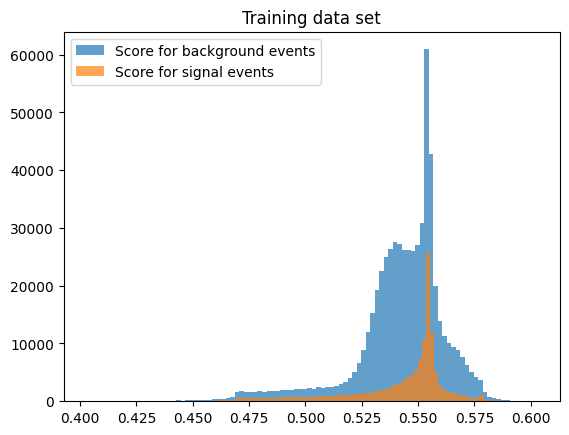

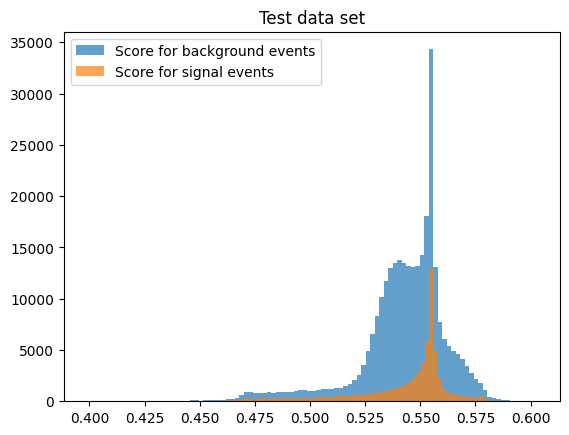

In [ ]:
nbins=100
plt.figure()
plt.hist(model(torch.tensor(X_train.to_numpy(),device=model.device)).numpy(force=True)[y_train==0], bins=nbins, alpha=0.7, label = "Score for background events")
plt.hist(model(torch.tensor(X_train.to_numpy(),device=model.device)).numpy(force=True)[y_train==1], bins=nbins, alpha=0.7, label = "Score for signal events")
plt.title("Training data set")
plt.legend(loc="best")
#plt.yscale("log")

plt.figure()
plt.hist(model(torch.tensor(X_test.to_numpy(),device=model.device)).numpy(force=True)[y_test==0], bins=nbins, alpha=0.7, label = "Score for background events")
plt.hist(model(torch.tensor(X_test.to_numpy(),device=model.device)).numpy(force=True)[y_test==1], bins=nbins, alpha=0.7, label = "Score for signal events")
plt.title("Test data set")
plt.legend(loc="best")
#plt.yscale("log")



We have learned how load the data into the GPU, how to define and instantiate a model. Now we need to define a training loop.

In `keras`, this is wrapped hidden into the `.fit()` method, which I think is bad because it hides the actual procedure.

In [ ]:
def train_loop(dataloader, model, loss_fn, optimizer, scheduler, device):
    size = len(dataloader.dataset)
    losses=[] # Track the loss function
    # Set the model to training mode - important for batch normalization and dropout layers

    # Unnecessary in this situation but added for best practices


    model.train()  # Modelo entra en MODO ENTRENAMIENTO
    #Le avisa a la red que puede hacer EL DROPOUT (apagar neuronas aleatoriammente)

    #En el test, model.test , NO se apagan neuronas


    #for batch, (X, y) in enumerate(dataloader):
    for (X,y) in tqdm(dataloader):
        # Reset gradients (to avoid their accumulation)
        optimizer.zero_grad()
        # Compute prediction and loss
        yhat = model(X)
        #if (all_equal3(pred.detach().numpy())):
        #    print("All equal!")


    #Los TENSORES en TORCH guardan el HISTORIAL DE GRADIENTE
    #Si queremos pasar un tensor a NUMPY para graficar
    #El TENSOR debe desactivar el gradiente
    #Esto se hace con "detach"

        loss = loss_fn(yhat.squeeze(dim=1), y)

        #Aqui se "desconecta" el hisotiral de gradiente, y manda todo a la CPU
        # Esto es paara que numpy pueda usar el tensor
        losses.append(loss.detach().cpu())


#------------------------------------------------------------------
#--------------------------BACKPROPAGATION----------------------
        # Backpropagation
        loss.backward()

        #Paso en la direccion de gradiente
        #"optimizer" guarda las estrategias de decenso de gradiente que debemos
        #de seguir
        optimizer.step()

        #------------IMPORTANTE----------
        #Ver como funciona lo del paso, cuanto de grande en el paso segun las epocas?

    scheduler.step()


    return np.mean(losses)

Now we need to define the loop that is run on the test dataset.

**The test dataset is just used for evaluating the output of the model. No backpropagation is needed, therefore backpropagation must be switched off!!!**

In [ ]:
def test_loop(dataloader, model, loss_fn, device):
    losses=[] # Track the loss function
    # Set the model to evaluation mode - important for batch normalization and dropout layers
    # Unnecessary in this situation but added for best practices
    model.eval()
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    test_loss, correct = 0, 0

    # Evaluating the model with torch.no_grad() ensures that no gradients are computed during test mode
    # also serves to reduce unnecessary gradient computations and memory usage for tensors with requires_grad=True

    with torch.no_grad():            #Desactivamos los gradientes mientras hacemos el TEST


        #for X, y in dataloader:
        for (X,y) in tqdm(dataloader):
            yhat = model(X)
            loss = loss_fn(yhat.squeeze(dim=1), y).item()
            losses.append(loss)
            test_loss += loss
            #correct += (pred.argmax(1) == y).type(torch.float).sum().item()

    return np.mean(losses)

We are now read to train this!
At the moment we are trying to do classification. We will set our loss function to be the cross entropy.

Torch provides the functionality to use generic functions as loss function. We will show an example one.

In [ ]:

#loss_fn = torch.nn.MSELoss()
loss_fn = torch.nn.CrossEntropyLoss()
#TORCH YA TRAE DEFINIDAS LAS LOSS FUNCIONES
#Solo hay que invocarlas


#loss_fn = torch.nn.CrossEntropyLoss(reduction='none')
def my_simple_loss(y_hat,y):
    loss = torch.mean( y[:,0]*torch.pow( y_hat - y[:,1], 2))
    #quad=-1,2
    #lin=-2,1
    #sm=-3,0
    return loss
# We would use this loss function in the same way as the other predefined loss functions:
# loss_fn=my_simple_loss


Time to define optimizer and scheduler, number of epochs, and finally to train!

Epoch 1
-------------------------------


100%|██████████| 2846/2846 [00:06<00:00, 445.74it/s]


Avg train loss 115.99167 , Avg test loss 115.82287841737899 Current learning rate [0.009000000000000001]
Epoch 2
-------------------------------


100%|██████████| 2846/2846 [00:07<00:00, 402.43it/s]

Avg train loss 115.991776 , Avg test loss 115.82259071736125 Current learning rate [0.008100000000000001]
Done!


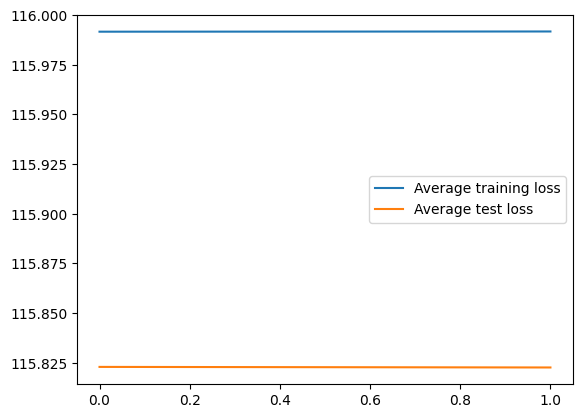

In [ ]:
epochs=2
learningRate = 0.01     #El valor inicial de la n. del leaning grade

#SGD - STOCHASTIC GRADIENT DESCENT
#ADAM- Otro algoritmo de descenso
optimizer = torch.optim.SGD(model.parameters(), lr=learningRate) #SGD, Adam
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.9)

train_losses=[]
test_losses=[]
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train_loss=train_loop(train_dataloader, model, loss_fn, optimizer, scheduler, device)
    test_loss=test_loop(test_dataloader, model, loss_fn, device)
    train_losses.append(train_loss)
    test_losses.append(test_loss)
    print("Avg train loss", train_loss, ", Avg test loss", test_loss, "Current learning rate", scheduler.get_last_lr())
print("Done!")


plt.plot(train_losses, label="Average training loss")
plt.plot(test_losses, label="Average test loss")
plt.legend(loc="best")

Output of the classifier

In [ ]:
nbins=100
plt.figure()
plt.hist(model(torch.tensor(X_train.to_numpy(),device=model.device)).numpy(force=True)[y_train==0], bins=nbins, alpha=0.7, label = "Score for background events")
plt.hist(model(torch.tensor(X_train.to_numpy(),device=model.device)).numpy(force=True)[y_train==1], bins=nbins, alpha=0.7, label = "Score for signal events")
plt.title("Training data set")
plt.legend(loc="best")
#plt.yscale("log")

plt.figure()
plt.hist(model(torch.tensor(X_test.to_numpy(),device=model.device)).numpy(force=True)[y_test==0], bins=nbins, alpha=0.7, label = "Score for background events")
plt.hist(model(torch.tensor(X_test.to_numpy(),device=model.device)).numpy(force=True)[y_test==1], bins=nbins, alpha=0.7, label = "Score for signal events")
plt.title("Test data set")
plt.legend(loc="best")
#plt.yscale("log")



In [ ]:
def plot_rocs(scores_labels_names):
    plt.figure()
    for score, label, name  in scores_labels_names:
        fpr, tpr, thresholds = roc_curve(label, score)
        plt.plot(
            fpr, tpr,
            linewidth=2,
            label=f"{name} (AUC = {100.*auc(fpr, tpr): .2f} %)"
        )
    plt.plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
    plt.grid()
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("Receiver Operating Characteristic curve")
    plt.legend(loc="lower right")
    plt.show()
    plt.close()

plot_rocs([
    (model(torch.tensor(X_train.to_numpy(),device=model.device)).numpy(force=True), y_train, "Train"),
    (model(torch.tensor(X_test.to_numpy(),device=model.device)).numpy(force=True), y_test, "Test")
])

## WHOOPS! The network is not learning anything!!!

What can we do?

Go back to that cell that had this text: `# LABEL OF THIS PLACE HERE, WILL BE USEFUL LATER`
and add there the following lines:


In [ ]:
from sklearn.preprocessing import StandardScaler

# NOTE: in earlier versions of the StandardScaler, `.values.reshape(-1,1)` was not needed. The interface must have changed.

for column in X_train.columns:
    scaler = StandardScaler().fit(X_train[column].values.reshape(-1,1))
    X_train[column] = scaler.transform(X_train[column].values.reshape(-1,1))
    X_test[column] = scaler.transform(X_test[column].values.reshape(-1,1))

You could also use the basic syntax recommended by the documentation, as follows, but then you would be standardizing all the features to exacly the same mean. This may work for some data sets, but for this specific one it does not (it actually significantly worsens the performance---you can try ;) ).

```
scaler = StandardScaler().fit(X_train)

X_train[X_train.columns] = scaler.transform(X_train[X_train.columns])
X_test[X_test.columns] = scaler.transform(X_test[X_test.columns])
```

Rerun starting from that cell, and now check the new loss function evolution.

#### Can you explain what is the effect of these lines and their effect on the gradient descent?

## WHOOPS! The network is not learning anything!!!

What can we do?

This new behaviour is likely caused by a too large value of initial learning rate, that makes training and test sink into two different minima. You can fix it by, for instance, reducing by a factor 10 the initial learning rate above.

## Multiclass

Go back to the original dataset, but now assign different labels to the two backgrounds

In [ ]:
signal = sig.drop(["Hreco_Lep2_pt", "Hreco_Lep2_eta", "Hreco_Lep2_phi", "Hreco_Lep2_mass", "Hreco_evt_tag", "Hreco_HTXS_Higgs_pt", "Hreco_HTXS_Higgs_y"], axis=1 )
bkg1 = bk1.drop(["Hreco_Lep2_pt", "Hreco_Lep2_eta", "Hreco_Lep2_phi", "Hreco_Lep2_mass", "Hreco_evt_tag","Hreco_HTXS_Higgs_pt", "Hreco_HTXS_Higgs_y"], axis=1 )
bkg2 = bk2.drop(["Hreco_Lep2_pt", "Hreco_Lep2_eta", "Hreco_Lep2_phi", "Hreco_Lep2_mass", "Hreco_evt_tag","Hreco_HTXS_Higgs_pt", "Hreco_HTXS_Higgs_y"], axis=1 )

signal['label'] = 2
bkg1['label'] = 1
bkg2['label'] = 0
bkg = pd.concat([bkg1, bkg2])

data = pd.concat([signal,bkg]).sample(frac=1).reset_index(drop=True)
X = data.drop(["label"], axis=1)
y = data["label"]


Now you need to apply the technique of **one-hot encoding** to convert a categorical label into a vector (one dimension per category/class).

Now you need to apply the technique of **one-hot encoding** to convert a categorical label (=0,1,2) into a vector (one dimension per category/class):


| Sample | Categorical | One-hot encoding |
| --- | --- | --- |
| Background 2 | $0$ | $(1,0,0)$ |
| Background 1 | $1$ | $(0,1,0)$ |
| Signal | $2$ | $(0,0,1)$ |


You can use the function `one_hot = torch.nn.functional.one_hot(target)` to one-hot encode the target labels (both for signal and background)

One-hot encoding is described in slide `81`of this morning's lecture.

You can use the function `one_hot = torch.nn.functional.one_hot(target)` to one-hot encode the target labels (both for signal and background)

In [ ]:
# Add this where appropriate
for label in [0,1,2]:
    one_hot = torch.nn.functional.one_hot(torch.tensor(label), num_classes=3)
    print (f"Encoding label '{label}' as '{one_hot.numpy(force=True)}'")

Next you need to recreate the test/train split, using the same lines of code you used for the simple classification problem


Next you have to modify the neural network model: the output must be a dimension-three vector rather than a scalar.

You can use `self.output = nn.Linear(8, 3)` as last layer, and you can prepend it a `SoftMax` or `sigmoid` activation function, to ensure the outputs are interpretable as probabilities



After training, you will need to figure out how to get categorical predictions to be able to test performance (for instance to produce the ROC curve for each pair of classes, or for one class against all the others.

However, the minimal useful thing is to produce the confusion matrix we have seen in this morning's lecture:

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
pred_y = model(torch.tensor(X_test.values, device=device)).numpy(force=True)
pred_class = np.argmax(pred_y,axis=1)
true_class = np.argmax(y_test.numpy(force=True),axis=1)

print (f"{'true class':10s} | {'predicted class':15s} ")
print ('='*30)
for i in range(10):
    print (f"{true_class[i]:<10d} | {pred_class[i]:<15d}")

confusion_mat = confusion_matrix(true_class, pred_class, normalize='true')

plt.figure()
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_mat, display_labels=['bkg2', 'bkg1', 'sig'])
disp.plot()
plt.show()
plt.close()

## Exercise

Calculate the predictions for each class, then plot the ROC curve for:

- signal vs bkg1
- signal vs bkg2
- bkg vs bkg2

Then, in another plot, plot:

- signal vs all backgrounds


# Regression

Go back to the original dataset, but now we will use the Higgs boson transverse momentum as a target for regression.
Notice how we avoid dropping the `Hreco_HTXS_Higgs_pt` column from the dataset, and we put that one into the target `y`.

The training will be done only on the signal (you want to regress the momentum in the specific process of interest).

We will still use the backgrounds, but just to make comparisons, in the sense that once you have the pT regressor, you can apply it to ttH (signal) events, but also separately to background events to see what's the shape of the regressed pT where the regressed pT is not supposed to exist (Drell-Yan events) or when it is supposed to exist but for another particle (W boson in ttW) events.

In [ ]:
signal = sig.drop(["Hreco_Lep2_pt", "Hreco_Lep2_eta", "Hreco_Lep2_phi", "Hreco_Lep2_mass", "Hreco_evt_tag", "Hreco_HTXS_Higgs_y"], axis=1 )
bkg1 = bk1.drop(["Hreco_Lep2_pt", "Hreco_Lep2_eta", "Hreco_Lep2_phi", "Hreco_Lep2_mass", "Hreco_evt_tag", "Hreco_HTXS_Higgs_y"], axis=1 )
bkg2 = bk2.drop(["Hreco_Lep2_pt", "Hreco_Lep2_eta", "Hreco_Lep2_phi", "Hreco_Lep2_mass", "Hreco_evt_tag", "Hreco_HTXS_Higgs_y"], axis=1 )

X = signal.drop(["Hreco_HTXS_Higgs_pt"], axis=1)
y = signal["Hreco_HTXS_Higgs_pt"]

`# MIMIMI HERE SOMETHING THERE WILL BE`

Now, since the target is a regression, we need to tweak two things.

First, the last activation function should not be a `nn.Sigmoid()` anymore (which forces the output to be in the range `[0,1]`. You should now use `nn.ReLU()`.

Second, the cross entropy loss is not appropriate anymore. You should use the `MSELoss()`.

With these two changes, you should be able to regress the Higgs boson transverse momentum.

Plot the loss function, and then produce a scatter plot of the neural network prediction versus the true value of the Higgs transverse momentum (`y` vs `pred=model(x)`). Finally, produce a plot where you show the shape of the pT regressor separately for the signal, for bkg1 (ttW),  and for bkg2 (Drell-Yan). For this latest plot, you should normalize to 1 the three distributions, to check for shape differences (you can use `density=True` when plotting).

## What is going on!?!??! Why is the loss always NotANumber?

This is because the network is not managing to cope with the vast range of values for the output (the pT).

Try reducing the range of values by adding, in correspondence of `# MIMIMI HERE SOMETHING THERE WILL BE`, the following transformation:


`y = signal["Hreco_HTXS_Higgs_pt"].apply(np.log)`

## Somehow better, but still suboptimal!

The spread of the predictions is too large to be used. Nonconvex optimization is difficult, and sometimes tweaking the model and training to success is tricky.

A way of hacking this problem is to use a more sophisticated loss function that penalizes predictions with different means. You can try!

```
class penalized_mse(nn.Module):
    def __init__(self):
        super().__init__()
        
    def forward(self, pred, target):
        #return ((pred-target)**2).mean() + 2*((torch.log(pred)-torch.log(target))**2).mean()
        print(pred.mean(), pred.var(),target.var())
        return ((pred-target)**2).mean()*(torch.abs(pred.var()-target.var()))

loss_fn=penalized_mse()
```

Also see if modifying the network can help to improve the prediction. For example ...
* add dropout layers
* use a different activation function
* add batch normalization layers
* reduce the number of layer
* reduce the number of nodes

### The end